# Reproducir la red neuronal publicada: sus semillas, sus anchos y cuánto vale su puntaje de validación

**Pregunta:** ¿Se puede reproducir la red publicada, y importa su ancho cuando se excluye una campaña completa?

**Nivel 3: Estado del arte** · Requiere: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites, 05-learned-arms/02-every-arm-and-why-each-one-refuses · Tiempo de lectura: unos 40 minutos

## Objetivos

Kulatilake, Hudaverdi y Wu 2012 entrenaron una red neuronal pequeña con este corpus y la informaron como el mejor de tres predictores en un conjunto de validación de 12 tiros. El motor implementa la red según su especificación publicada. Este notebook le hace dos preguntas a ese resultado. ¿Se puede reproducir la red, y cuánto vale el puntaje publicado una vez que se varía la inicialización aleatoria? ¿Y importa el ancho oculto que eligieron los autores cuando se excluye una campaña completa?

Al terminar habrá:

- encaminado los 12 tiros de validación a su grupo de rigidez con el discriminante publicado y entrenado la red del motor con el corpus;
- comparado las predicciones reproducidas con la columna impresa y con las mediciones, tiro a tiro;
- reentrenado la red con 30 semillas y ubicado el puntaje impreso entre ellas;
- repetido la selección de ancho de los autores y luego puntuado seis anchos y el par publicado con cada campaña excluida por turno.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación importa los paquetes y la clase de la red, `PublishedNeuralNetwork`, imprime las versiones, carga el corpus y los 12 tiros de validación del artículo de 2012 (`protocol="2012"`), y define `Table`. Importa `json` para la única comprobación de reproducción del final.

In [1]:
# Importaciones, versiones de los paquetes y el cargador del corpus
from importlib.metadata import version
from pathlib import Path
import json

from blastfrag.learned import PublishedNeuralNetwork

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "tiros de", len({b.site for b in train}), "campañas")

class Table:
    """Filas bajo un encabezado, mostradas como tabla Markdown"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

holdout = bf.load_holdout(protocol="2012")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 tiros de 10 campañas


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros de entrenamiento y los 12 tiros de validación con las predicciones impresas de la red | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; los artículos nunca se distribuyen | el corpus y `bf.load_holdout(protocol="2012")` dentro del paquete `blastfrag` |
| El barrido por semilla que escribió la ejecución offline, para la única comprobación de reproducción | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campo `network_seed_sweep` |

La validación incluye el tiro `Rc1`, que también es un tiro de entrenamiento: el motor lleva esa marca de filtración en el registro, y el puntaje impreso es el que informa el artículo, con ese tiro dentro.

## Método

La red de Kulatilake et al. 2012 (https://doi.org/10.1007/s10706-012-9496-3, sección 5) está especificada con el detalle suficiente para reproducirla:

- una red por grupo de rigidez de la roca, cada una entrenada solo con las filas de ese grupo; el grupo de un tiro sale de la función discriminante publicada por Hudaverdi et al. 2010 (https://doi.org/10.1002/nag.957) y no de la etiqueta del corpus, así que un tiro que el corpus nunca vio se encamina igual;
- siete entradas, una capa oculta con activación logística, una salida, y normalización mín-máx de entradas y objetivo (su Ec. 11);
- entrenamiento de Levenberg-Marquardt, ocho simulaciones por ancho promediadas, y un ancho oculto barrido de 6 a 15 y elegido en la validación por RMSE y correlación, lo que dio 9 para el primer grupo y 7 para el segundo.

De esta especificación se siguen dos propiedades que importan más abajo. El ancho se elige con los mismos 12 tiros con que luego se puntúa la red, y los pesos dependen de una inicialización aleatoria que el artículo no informa. El puntaje en todo el notebook es `r2_identity`, la varianza explicada respecto de la línea 1:1.

### Paso 1: encaminar los tiros a su grupo

`assign_group` aplica el discriminante publicado a un tiro, y `discriminant_score` da el puntaje detrás de la decisión: sobre el límite un tiro pertenece al grupo 1 de módulo alto, bajo él al grupo 2. La celda cuenta los tiros de entrenamiento de cada grupo y encamina los 12 tiros de validación.

In [2]:
# Encaminar los 12 tiros de validación y contar los tiros de entrenamiento de cada grupo de rigidez
groups = [bf.assign_group(blast) for blast in train]
print("tiros de entrenamiento por grupo (1 = módulo alto, 2 = bajo):", {g: groups.count(g) for g in (1, 2)})
rows = [(b.blast_id, b.site, f"{b.E_GPa:.1f}", f"{bf.discriminant_score(b):+.2f}", bf.assign_group(b),
    b.group) for b in holdout]
Table(["tiro", "campaña", "E (GPa)", "puntaje del discriminante", "enviado a", "etiqueta del corpus"], rows)

tiros de entrenamiento por grupo (1 = módulo alto, 2 = bajo): {1: 35, 2: 62}


| tiro | campaña | E (GPa) | puntaje del discriminante | enviado a | etiqueta del corpus |
|---|---|---|---|---|---|
| En13 | Enusa | 60.0 | +17.69 | 1 | 1 |
| Ru7 | Reocin-UG | 45.0 | +15.17 | 1 | 1 |
| Mg8 | Murgul | 50.0 | +13.88 | 1 | 1 |
| Mg9 | Murgul | 50.0 | +13.06 | 1 | 1 |
| Rc1 | Reocin | 45.0 | +15.11 | 1 | 1 |
| Mr12 | Mrica | 32.0 | +8.40 | 2 | 2 |
| Db10 | Dongri-Buzurg | 9.6 | +6.36 | 2 | 2 |
| Sm8 | Soma | 13.2 | +7.28 | 2 | 2 |
| Oz8 | Ozmert | 15.0 | +7.58 | 2 | 2 |
| Oz9 | Ozmert | 15.0 | +6.67 | 2 | 2 |
| Ad23 | Akdaglar | 16.9 | +6.76 | 2 | 2 |
| Ad24 | Akdaglar | 16.9 | +8.75 | 2 | 2 |

**Qué muestra la salida.** El corpus tiene 35 tiros de módulo alto y 62 de módulo bajo, así que el grupo 1 se entrena con poco más de un tercio de los datos. El discriminante envía al grupo 1 los cinco tiros de validación con un módulo de 45 GPa o más (Enusa, Reocin-UG, Murgul y Reocin), y al grupo 2 los siete de 32 GPa o menos, con puntajes entre 6,36 y 8,75 para el grupo 2 y entre 13,06 y 17,69 para el grupo 1. Coincide con la etiqueta del corpus en los doce. **Qué no muestra:** cuán cerca del límite puede quedar un tiro nuevo; ninguno de estos doce lo está.

### Paso 2: reproducir las predicciones impresas

La celda entrena una vez la reproducción del motor, con semilla 0, sobre todo el corpus y predice los 12 tiros. Puntúa el resultado y la columna impresa del artículo, y también los otros dos predictores que imprime el artículo, una regresión y una columna Kuz-Ram, para poder comprobar la afirmación "el mejor de tres".

In [3]:
# Ajustar una vez la reproducción del motor (semilla 0) y compararla con la columna impresa y las mediciones
network = PublishedNeuralNetwork(seed=0).fit(train)
reproduced = network.predict(holdout)
printed = [bf.Prediction(method="published", blast_id=b.blast_id,
    x50_m=b.meta["published"]["nn_mean_2012"]) for b in holdout]
published_score = bf.score(holdout, printed)
seed0_score = bf.score(holdout, reproduced)
rows = [(b.blast_id, f"{b.x50_m:.2f}", f"{q.x50_m:.2f}", f"{p.x50_m:.3f}") for b, q,
    p in zip(holdout, printed, reproduced)]
other_columns = {}
for key in ("regression_2012", "kuzram_2012"):
    column = [bf.Prediction(method=key, blast_id=b.blast_id, x50_m=b.meta["published"][key]) for b in holdout]
    other_columns[key] = bf.score(holdout, column).r2_identity
print("r2 impreso de los otros dos predictores del artículo:", {k: round(v, 3) for k, v in other_columns.items()})
print(f"r2 columna impresa = {published_score.r2_identity:.3f} (RMSE {published_score.rmse_m:.3f} m) | "
      f"r2 reproducida, semilla 0 = {seed0_score.r2_identity:.3f} (RMSE {seed0_score.rmse_m:.3f} m)")
Table(["tiro", "medido (m)", "impreso (m)", "reproducido (m)"], rows)

r2 impreso de los otros dos predictores del artículo: {'regression_2012': 0.708, 'kuzram_2012': 0.232}
r2 columna impresa = 0.910 (RMSE 0.044 m) | r2 reproducida, semilla 0 = 0.309 (RMSE 0.121 m)


| tiro | medido (m) | impreso (m) | reproducido (m) |
|---|---|---|---|
| En13 | 0.47 | 0.42 | 0.419 |
| Ru7 | 0.64 | 0.63 | 0.428 |
| Mg8 | 0.44 | 0.37 | 0.374 |
| Mg9 | 0.25 | 0.28 | 0.255 |
| Rc1 | 0.46 | 0.43 | 0.460 |
| Mr12 | 0.20 | 0.12 | 0.160 |
| Db10 | 0.35 | 0.33 | 0.687 |
| Sm8 | 0.18 | 0.19 | 0.190 |
| Oz8 | 0.23 | 0.15 | 0.136 |
| Oz9 | 0.17 | 0.19 | 0.180 |
| Ad23 | 0.21 | 0.21 | 0.225 |
| Ad24 | 0.20 | 0.19 | 0.211 |

La celda siguiente grafica el tamaño medido contra lo que imprimió el artículo (círculos verdes) y contra lo que reprodujo el motor (cuadrados naranjas), con la línea 1:1 de referencia. Mire cuán cerca de la línea está cada conjunto de puntos y qué tiros pierde más la reproducción.

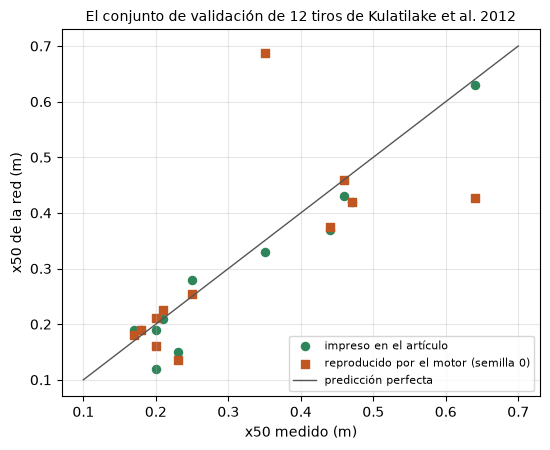

In [4]:
# Tamaño medido contra impreso y reproducido en los 12 tiros de validación
measured = np.array([b.x50_m for b in holdout])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.scatter(measured, [q.x50_m for q in printed], s=34, color="#2f855a", label="impreso en el artículo")
ax.scatter(measured, [p.x50_m for p in reproduced], s=34, marker="s", color="#c05621",
    label="reproducido por el motor (semilla 0)")
ax.plot([0.1, 0.7], [0.1, 0.7], color="#555", lw=1, label="predicción perfecta")
ax.set_xlabel("x50 medido (m)")
ax.set_ylabel("x50 de la red (m)")
ax.set_title("El conjunto de validación de 12 tiros de Kulatilake et al. 2012", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** La columna impresa (círculos verdes) se pega a la línea 1:1: su r2 es 0,910 y su RMSE 0,044 m, frente a 0,708 de la regresión del artículo y 0,232 de su columna Kuz-Ram, así que la red es en efecto la mejor de los tres predictores impresos. La reproducción (cuadrados naranjas) sigue la misma tendencia pero con fallos visibles, r2 0,309 y RMSE 0,121 m, los mayores en Db10 (0,687 m predicho para 0,35 m medido, donde el artículo imprime 0,33 m) y en Ru7 (0,428 m para 0,64 m). **Qué no muestra:** cuál de las dos es la red típica. Una semilla es una extracción, y las celdas siguientes hacen 30. **Qué se sigue:** la especificación por sí sola no reproduce el puntaje impreso.

## Estado del arte

El estado del arte para este predictor es el propio artículo, y lo que establece es más acotado de lo que un lector de su resumen podría suponer.

- **Kulatilake, Hudaverdi y Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) es la referencia de la red: la especificación de la sección Método y una validación de 12 tiros en la que es el mejor de tres predictores impresos (paso 2).
- La red se informa como una instancia entrenada. El artículo no da dispersión sobre la inicialización de pesos, así que el puntaje impreso es una sola extracción.
- El ancho oculto se elige con los mismos 12 tiros con que se puntúa la red, así que el puntaje es un óptimo sobre anchos en su propio conjunto de prueba.
- No se excluye ninguna campaña: los 12 tiros vienen de nueve de las diez campañas que también aportan las filas de entrenamiento.

Los tres pasos siguientes prueban cada límite con el motor: la semilla (paso 3), la selección de ancho (paso 4) y la campaña excluida (paso 5).

### Paso 3: la semilla

El entrenamiento parte de pesos aleatorios, y `seed` los fija. La celda reentrena la red completa 30 veces con las semillas de 0 a 29, puntúa cada vez los 12 tiros de validación y resume los 30 puntajes con `summarise_draws`. Demora cerca de medio minuto.

In [5]:
# Reentrenar la red con 30 semillas de inicialización de pesos y puntuar cada vez los 12 tiros de validación, unos
# treinta segundos
seed_scores = []
for seed in range(30):
    trained = PublishedNeuralNetwork(seed=seed).fit(train)
    seed_scores.append(bf.score(holdout, trained.predict(holdout)).r2_identity)
seed_scores = np.sort(seed_scores)
summary = bf.summarise_draws(list(seed_scores))
print(f"columna impresa r2 = {published_score.r2_identity:.3f}")
print("30 semillas reproducidas:", f"min {seed_scores.min():.3f} | p25 {summary['p25']:.3f}",
      f"| median {summary['median']:.3f} | p75 {summary['p75']:.3f} | max {seed_scores.max():.3f}")
print("semillas que alcanzan el puntaje impreso:", int((seed_scores >= published_score.r2_identity).sum()))

columna impresa r2 = 0.910
30 semillas reproducidas: min 0.167 | p25 0.299 | median 0.340 | p75 0.462 | max 0.636
semillas que alcanzan el puntaje impreso: 0


La celda siguiente dibuja los 30 puntajes en un solo eje, con el puntaje impreso como línea naranja y la mediana de las semillas como línea de trazos. Toda la información está en la posición horizontal: busque el lugar de la línea naranja entre los puntos azules.

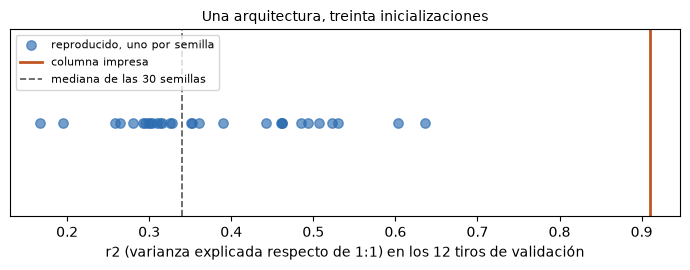

In [6]:
# Los 30 puntajes reproducidos como una franja, con el puntaje impreso como línea vertical
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.scatter(seed_scores, np.zeros(len(seed_scores)), s=46, alpha=0.65, color="#2b6cb0",
    label="reproducido, uno por semilla")
ax.axvline(published_score.r2_identity, color="#c05621", lw=2, label="columna impresa")
ax.axvline(np.median(seed_scores), color="#555", lw=1.2, ls="--", label="mediana de las 30 semillas")
ax.set_yticks([])
ax.set_xlabel("r2 (varianza explicada respecto de 1:1) en los 12 tiros de validación")
ax.set_title("Una arquitectura, treinta inicializaciones", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Los 30 puntajes reproducidos están entre 0,167 y 0,636, con una mediana de 0,340 y una mitad central entre 0,299 y 0,462, y ninguno alcanza el 0,910 impreso (la línea naranja, muy a la derecha). La semilla sola mueve el puntaje de validación de la red en un rango casi tan ancho como la brecha entre la regresión del artículo (0,708) y su columna Kuz-Ram (0,232). **Qué no muestra:** que los autores informaran mal la red: existe en principio una inicialización favorable, y el artículo pudo elegir entre varias. **Qué se sigue:** el puntaje impreso es una propiedad de una instancia entrenada que la especificación no reproduce, no una propiedad de la arquitectura, y 0 de 30 semillas lo recuperan.

### Paso 4: la selección de ancho

`sweep_hidden_width` repite el procedimiento de los autores: para cada ancho de 6 a 15 entrena la red y puntúa los tiros de validación de cada grupo, y elige el ancho con el menor RMSE. La celda imprime el ancho que elige junto al publicado y el mejor y el peor RMSE de cada grupo, y la figura dibuja la curva completa de RMSE. Demora cerca de un minuto.

In [7]:
# Repetir la selección de ancho de la fuente: entrenar cada ancho de 6 a 15, cerca de un minuto
sweep = PublishedNeuralNetwork(n_simulations=8, seed=0).sweep_hidden_width(train, holdout)
rows = []
for group, entry in sweep.items():
    best = min(entry["table"], key=lambda r: r["rmse"])
    worst = max(entry["table"], key=lambda r: r["rmse"])
    rows.append((group, entry["published_optimum"], entry["best_hidden"], f"{best['rmse']:.3f}",
        f"{worst['rmse']:.3f}", worst["hidden"]))
Table(["grupo", "ancho publicado", "ancho elegido aquí", "mejor RMSE (m)", "peor RMSE (m)", "peor ancho"], rows)

| grupo | ancho publicado | ancho elegido aquí | mejor RMSE (m) | peor RMSE (m) | peor ancho |
|---|---|---|---|---|---|
| 1 | 9 | 8 | 0.037 | 0.109 | 13 |
| 2 | 7 | 11 | 0.106 | 0.157 | 12 |

La celda siguiente dibuja, para cada grupo de rigidez, el RMSE de la red en la validación en función del ancho oculto, con la elección publicada en naranja y la elección de esta reproducción en verde. Mire cuán irregulares son las curvas y la distancia entre las dos líneas verticales.

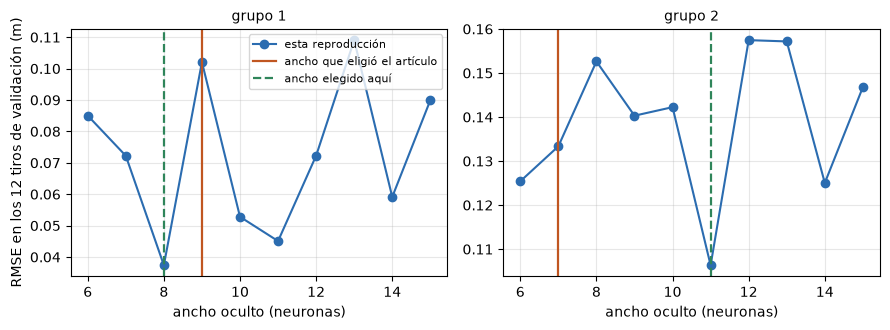

In [8]:
# RMSE en la validación contra el ancho oculto, una línea por grupo de rigidez
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, (group, entry) in zip(axes, sweep.items()):
    widths = [r["hidden"] for r in entry["table"]]
    ax.plot(widths, [r["rmse"] for r in entry["table"]], "o-", color="#2b6cb0", label="esta reproducción")
    ax.axvline(entry["published_optimum"], color="#c05621", lw=1.6, label="ancho que eligió el artículo")
    ax.axvline(entry["best_hidden"], color="#2f855a", lw=1.6, ls="--", label="ancho elegido aquí")
    ax.set_title(f"grupo {group}", fontsize=10)
    ax.set_xlabel("ancho oculto (neuronas)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("RMSE en los 12 tiros de validación (m)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** La selección no cae en los anchos publicados. Para el grupo 1 elige el ancho 8 (RMSE 0,037 m) donde el artículo eligió 9; para el grupo 2 elige el ancho 11 (RMSE 0,106 m) donde el artículo eligió 7. Las curvas son quebradas: en el grupo 1 el RMSE va de 0,037 m en el ancho 8 a 0,109 m en el ancho 13, y anchos vecinos difieren tanto como los extremos, así que el óptimo es el punto más bajo de una curva ruidosa ajustada con 5 y 7 tiros más que un mínimo claro. **Qué no muestra:** que alguna de las dos elecciones sea mejor fuera de la validación. **Qué se sigue:** el ancho es un número afinado en el conjunto de prueba, así que el puntaje impreso es optimista por construcción, y el paso siguiente pregunta si algún ancho se transfiere a una campaña que no ha visto.

### Paso 5: el ancho con una campaña excluida

El protocolo del producto deja fuera cada una de las diez campañas por turno y entrena una red nueva con las otras nueve. La celda lo hace para el par publicado de anchos (9, 7) y para seis anchos usados en ambos grupos, de 6 a 11, agrupa las 97 predicciones fuera de pliegue de cada configuración y las puntúa, con el nulo (la media de entrenamiento) como referencia. Entrena 70 redes y demora cerca de dos minutos.

In [9]:
# Leave-one-site-out para seis anchos y el par publicado; cada pliegue entrena una red nueva, unos dos minutos
folds = list(bf.leave_one_site_out(train))
tested = [blast for fold in folds for blast in fold.test]
published = PublishedNeuralNetwork(hidden=dict(bf.PUBLISHED_NETWORK_WIDTHS))
pair = [p for fold in folds for p in published.fit(fold.train).predict(fold.test)]
pair_score = bf.score(tested, pair)
held_out = {}
for width in range(6, 12):
    predicted = [p for fold in folds for p in PublishedNeuralNetwork(hidden={1: width,
        2: width}).fit(fold.train).predict(fold.test)]
    held_out[width] = bf.score(tested, predicted)
null_score = bf.score(tested, [p for fold in folds for p in bf.NullModel().fit(fold.train).predict(fold.test)])
rows = [(f"{width}, {width}", f"{s.r2_identity:.3f}", f"{s.rmse_m:.3f}") for width, s in held_out.items()]
rows += [("publicado (9, 7)", f"{pair_score.r2_identity:.3f}", f"{pair_score.rmse_m:.3f}")]
rows += [("nulo", f"{null_score.r2_identity:.3f}", f"{null_score.rmse_m:.3f}")]
Table(["anchos (grupo 1, grupo 2)", "r2", "RMSE (m)"], rows)

| anchos (grupo 1, grupo 2) | r2 | RMSE (m) |
|---|---|---|
| 6, 6 | -0.605 | 0.237 |
| 7, 7 | -0.653 | 0.241 |
| 8, 8 | -0.626 | 0.239 |
| 9, 9 | -0.586 | 0.236 |
| 10, 10 | -0.902 | 0.258 |
| 11, 11 | -0.568 | 0.235 |
| publicado (9, 7) | -0.626 | 0.239 |
| nulo | -0.216 | 0.207 |

La celda siguiente dibuja el puntaje con campaña excluida de cada ancho como una línea azul, con el par publicado como línea naranja y el nulo como línea de trazos. La línea de trazos es la valla que hay que superar: mire si algún punto de la línea azul queda sobre ella.

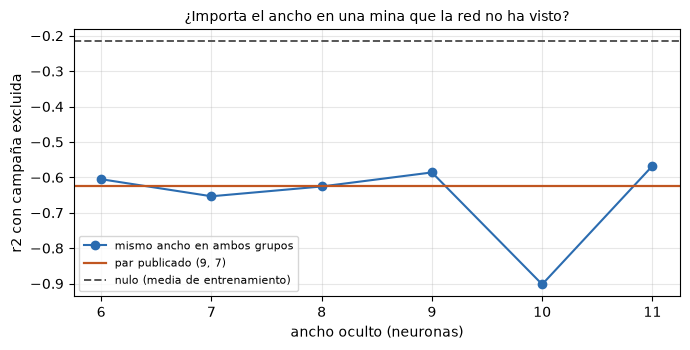

In [10]:
# Puntaje con campaña excluida contra ancho oculto, junto al par publicado y el nulo
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(list(held_out), [s.r2_identity for s in held_out.values()], "o-", color="#2b6cb0",
    label="mismo ancho en ambos grupos")
ax.axhline(pair_score.r2_identity, color="#c05621", lw=1.6, label="par publicado (9, 7)")
ax.axhline(null_score.r2_identity, color="#555", ls="--", lw=1.4, label="nulo (media de entrenamiento)")
ax.set_xlabel("ancho oculto (neuronas)")
ax.set_ylabel("r2 con campaña excluida")
ax.set_title("¿Importa el ancho en una mina que la red no ha visto?", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Todo ancho puntúa bajo el nulo (la línea de trazos en -0,216). Los seis anchos están entre -0,568 (ancho 11) y -0,902 (ancho 10), y el par publicado (9, 7), la línea naranja, puntúa -0,626, en medio de esa banda. El RMSE casi no se mueve con el ancho, de 0,235 m a 0,258 m, frente a 0,207 m del nulo. La curva no es monótona: el ancho 10 es el peor y el 11 el mejor, dos anchos vecinos, que es otra vez la inestabilidad vista en el paso 4. **Qué no muestra:** que ninguna red podría transferirse, solo que esta arquitectura con las filas de entrenamiento de estos pliegues no lo hace, en ningún ancho probado. **Qué se sigue:** afinar el ancho en una validación de las mismas campañas no compra nada en una campaña que no ha visto.

### Comprobación de reproducción: el barrido por semilla de la ejecución offline

Los 30 puntajes por semilla del paso 3 son los que la ejecución offline escribió en `benchmark.json`, así que deben ser iguales. La celda imprime la mayor diferencia.

In [11]:
# La única comprobación de reproducción: los 30 puntajes por semilla igualan el barrido que escribió la ejecución
# offline
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
baked = benchmark["network_seed_sweep"]["r2_identity"]
print("mayor diferencia con el barrido por semilla de la ejecución offline:",
    f"{np.max(np.abs(np.sort(baked) - seed_scores)):.1e}")

mayor diferencia con el barrido por semilla de la ejecución offline: 0.0e+00


## Resultados

**Respuesta:** la red publicada puede reproducirse según su especificación pero no según su puntaje, y su ancho no importa cuando se excluye una campaña porque ningún ancho ayuda. La red impresa puntúa r2 0,910 en los 12 tiros de validación; la reproducción del motor puntúa 0,309 con la semilla 0, y en 30 semillas el puntaje va de 0,167 a 0,636 con una mediana de 0,340, así que 0 de 30 llegan al valor impreso. Al repetir la selección de ancho de los autores se eligen 8 y 11 donde ellos eligieron 9 y 7, sobre curvas de RMSE que se mueven de 0,037 m a 0,109 m entre anchos de un mismo grupo. Con cada una de las diez campañas excluida por turno, el par publicado puntúa -0,626 (RMSE 0,239 m), los seis anchos de 6 a 11 entre -0,568 y -0,902, y el nulo -0,216 (RMSE 0,207 m): ningún ancho alcanza al nulo.

El puntaje publicado es así lo mejor de varias cosas a la vez: una inicialización favorable, un ancho afinado en los tiros de prueba y una validación cuyas campañas también están en el entrenamiento. Cada una le quita parte de su significado, y el producto informa en su lugar la cifra con campaña excluida.

**Qué no muestra esto.** No muestra que los autores se equivocaran: una inicialización puede superar la mediana de muchas, y pudieron elegir entre varias. No muestra que ninguna red neuronal pueda predecir una campaña nueva; la red probada aquí es la publicada, con 97 filas. Y las 30 semillas y las 70 redes son un experimento acotado, no una distribución de todo entrenamiento posible.

## Resumen

- La red se encamina con el discriminante publicado (35 y 62 tiros de entrenamiento por grupo) y se reproduce desde su especificación; con la semilla 0 puntúa 0,309 en la validación donde el artículo imprime 0,910.
- En 30 semillas el puntaje va de 0,167 a 0,636, y ninguna alcanza el valor impreso; la selección de ancho elige 8 y 11 frente a los 9 y 7 publicados.
- Con cada campaña excluida, todo ancho puntúa entre -0,568 y -0,902, bajo el nulo en -0,216, y el par publicado obtiene -0,626.
- Siguiente: el tema 06 pregunta cómo responde una predicción cuando cambia el diseño.

## Referencias

- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red de retropropagación y su conjunto de validación)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/